<a href="https://colab.research.google.com/github/HedarBilgec/skills-introduction-to-github/blob/main/Hafta_9_Odev.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Görüntü İşleme: Renk Uzayları ve OpenCV Uygulamaları

## Task-1: Renk Uzaylarının Karşılaştırılması ve Kullanım Alanları

Renk uzayları, renklerin matematiksel olarak ifade edilmesini sağlayan koordinat sistemleridir. Farklı problemler, ışık koşulları veya donanım gereksinimleri sebebiyle farklı renk uzayları tercih edilir.

### 1. RGB (Red, Green, Blue)
* **Açıklama:** Ekranlar, kameralar ve dijital tarayıcılar tarafından kullanılan, birincil ışık renklerinin (Kırmızı, Yeşil, Mavi) birleşimine dayanan eklemeli (additive) bir renk uzayıdır.
* **Avantajları:**
  * Donanımlarla (ekran, kamera sensörleri) doğrudan uyumludur.
  * Anlaşılması ve piksel düzeyinde manipülasyonu kolaydır.
* **Dezavantajları:**
  * Işık şiddeti (aydınlık/parlaklık) değişimlerinden aşırı derecede etkilenir. Kırmızı bir nesnenin üzerine gölge düştüğünde R, G ve B bileşenlerinin üçü birden değişir.
  * İnsan gözünün algısal yapısıyla uyumlu değildir.
* **Kullanım Alanları:** Görüntülerin ekranda gösterilmesi, genel kayıt işlemleri ve basit piksel filtrelemeleri.

### 2. HSV (Hue, Saturation, Value) / HSI (Hue, Saturation, Intensity)
* **Açıklama:** Rengi; özü (Hue - renk türü/açısı), doygunluğu (Saturation - rengin canlılığı) ve parlaklığı (Value/Intensity - ışık miktarı) olarak ayırır.
* **Avantajları:**
  * Renk bilgisi (H) ile parlaklık bilgisi (V/I) tamamen birbirinden ayrılmıştır. Bu sayede gölgelerden veya değişen ışık koşullarından etkilenmeden renk tespiti yapılabilir.
  * İnsanların rengi tanımlama şekline çok yakındır (Örn: "Koyu canlı kırmızı").
* **Dezavantajları:**
  * RGB'ye göre dönüşüm işlemi ek matematiksel işlem yükü getirir.
* **Kullanım Alanları:** Renk tabanlı nesne tespiti/takibi, histogram eşitleme ile kontrast artırma.

### 3. YUV / YCbCr
* **Açıklama:** Y aydınlık (Luma/Luminance) bileşenini, U/V veya Cb/Cr ise renk farkı (Chrominance) bileşenlerini temsil eder.
* **Avantajları:**
  * İnsan gözü parlaklık (detay) değişimlerine renk değişimlerinden çok daha duyarlıdır. YUV/YCbCr renk bilgisini sıkıştırarak (Chroma Subsampling) insan gözünün fark edemeyeceği kalitede yüksek veri tasarrufu sağlar.
* **Dezavantajları:**
  * Doğrudan görselleştirilmesi RGB gibi sezgisel değildir.
* **Kullanım Alanları:** Televizyon yayıncılığı (PAL/NTSC), video sıkıştırma formatları (MPEG, JPEG, H.264), insan ten rengi tespiti.

### 4. CIE L*a*b*
* **Açıklama:** L* açıklığı (Lightness), a* yeşil-kırmızı eksenini, b* ise mavi-sarı eksenini belirtir. İnsan algısına göre tasarlanmış cihazdan bağımsız standart bir renk uzayıdır.
* **Avantajları:**
  * **Algısal Tekdüzelik (Perceptual Uniformity):** İki renk arasındaki geometrik mesafe (Euclidean distance), insanların bu renk farkını algılama derecesine doğrudan karşılık gelir.
* **Dezavantajları:**
  * Dönüşüm formülleri oldukça karmaşıktır ve işlem maliyeti yüksektir.
* **Kullanım Alanları:** Hassas renk ölçümü, matbaacılık, cihazlar arası renk kalibrasyonu.

### 5. Grayscale (Gri Tonlama)
* **Açıklama:** Görüntünün renk bilgilerinden arındırılıp sadece parlaklık (ışık yoğunluğu) değerini ($[0, 255]$) barındırdığı tek kanallı yapıdır.
* **Avantajları:**
  * Veri boyutunu 3 kat azaltır.
  * Kenar bulma, köşe tespiti ve nesne tanıma gibi yapısal analizlerde renk bilgisine ihtiyaç duyulmadığı için işlem hızını muazzam ölçüde artırır.
* **Dezavantajları:**
  * Renk farkı ile ayırt edilebilen nesnelerin bilgisini kaybettirir.
* **Kullanım Alanları:** Kenar algılama (Edge detection), morfolojik işlemler, yüz tanırma, örüntü eşleştirme.

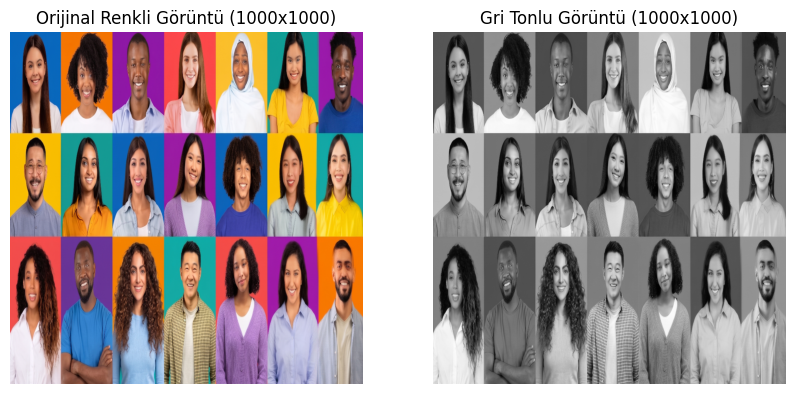

--- Boyut Kıyaslaması (1000x1000 Çözünürlük) ---
Renkli BMP (3 Kanal) Dosya Boyutu: 2.8611 MB
Gri Tonlu BMP (1 Kanal) Dosya Boyutu: 0.9547 MB
Teorik Oran (Renkli / Gri): 3.00 (Beklenen: ~3 kat)


In [16]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Resmin yüklenmesi
img_path = '/content/Gemini_Generated_Image_gmtbuhgmtbuhgmtb.jpg'
original_bgr = cv2.imread(img_path)

# OpenCV varsayılan olarak BGR yükler. 1000x1000 boyutuna yeniden boyutlandıralım (Task-2 gereksinimi)
resized_rgb = cv2.resize(cv2.cvtColor(original_bgr, cv2.COLOR_BGR2RGB), (1000, 1000))

# Ekranda Gösterme
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(resized_rgb)
plt.title('Orijinal Renkli Görüntü (1000x1000)')
plt.axis('off')

# 2. Gri tonlu resme dönüştürme
gray_img = cv2.cvtColor(resized_rgb, cv2.COLOR_RGB2GRAY)

plt.subplot(1, 2, 2)
plt.imshow(gray_img, cmap='gray')
plt.title('Gri Tonlu Görüntü (1000x1000)')
plt.axis('off')
plt.show()

# 3. BMP Formatında kaydetme
color_bmp_path = '/content/color_1000x1000.bmp'
gray_bmp_path = '/content/gray_1000x1000.bmp'

# OpenCV imwrite BGR beklediğinden dönüştürerek kaydediyoruz
cv2.imwrite(color_bmp_path, cv2.cvtColor(resized_rgb, cv2.COLOR_RGB2BGR))
cv2.imwrite(gray_bmp_path, gray_img)

# Dosya boyutlarını kontrol etme
color_size = os.path.getsize(color_bmp_path) / (1024 * 1024) # MB cinsinden
gray_size = os.path.getsize(gray_bmp_path) / (1024 * 1024) # MB cinsinden

print(f"--- Boyut Kıyaslaması (1000x1000 Çözünürlük) ---")
print(f"Renkli BMP (3 Kanal) Dosya Boyutu: {color_size:.4f} MB")
print(f"Gri Tonlu BMP (1 Kanal) Dosya Boyutu: {gray_size:.4f} MB")
print(f"Teorik Oran (Renkli / Gri): {color_size / gray_size:.2f} (Beklenen: ~3 kat)")

In [17]:
import cv2
import numpy as np
import time

# 1. 8K Çözünürlükte (7680 x 4320) 3 Kanallı (RGB) Rastgele/Örnek bir resim oluşturalım
width, height = 7680, 4320
print("8K resim oluşturuluyor...")
# Bellekte yer kaplaması ve gerçekçi olması için rastgele gürültü ve desen içeren bir 8K matris
test_8k_img = np.random.randint(0, 256, (height, width, 3), dtype=np.uint8)

# Disk üzerinde bir ilk BMP dosyası olarak kaydedelim
initial_8k_path = '/content/initial_8k.bmp'
cv2.imwrite(initial_8k_path, test_8k_img)
print(f"Orijinal 8K Resim kaydedildi: {initial_8k_path}")

# 2. Resmi OpenCV kullanarak tekrar açalım
loaded_8k_img = cv2.imread(initial_8k_path)

# 3. Sadece düzenleme kısmı (her pikseli 2'ye bölme) için geçen süreyi hassas şekilde ölçelim
start_time = time.perf_counter()

# Piksel değerlerini 2'ye bölme işlemi
# Not: Doğrudan loaded_8k_img // 2 veya loaded_8k_img / 2 işlemini yapabiliriz.
# Tam sayı bölmesi (integer division) veri tipini korumak için en verimli yaklaşımdır.
edited_8k_img = loaded_8k_img // 2

end_time = time.perf_counter()
elapsed_time_ms = (end_time - start_time) * 1000

# 4. Düzenlenen resmi bmp formatında kaydedelim
output_8k_path = '/content/edited_8k.bmp'
cv2.imwrite(output_8k_path, edited_8k_img)

print(f"\n--- Task-3 Sonuçları ---")
print(f"Resim Çözünürlüğü: {loaded_8k_img.shape[1]}x{loaded_8k_img.shape[0]} (8K)")
print(f"Kanal Sayısı: {loaded_8k_img.shape[2]}")
print(f"Düzenleme Süresi (Pikselleri 2'ye bölme): {elapsed_time_ms:.4f} milisaniye ({elapsed_time_ms/1000:.6f} saniye)")
print(f"Düzenlenen Resim Kaydedildi: {output_8k_path}")

8K resim oluşturuluyor...
Orijinal 8K Resim kaydedildi: /content/initial_8k.bmp

--- Task-3 Sonuçları ---
Resim Çözünürlüğü: 7680x4320 (8K)
Kanal Sayısı: 3
Düzenleme Süresi (Pikselleri 2'ye bölme): 33.6654 milisaniye (0.033665 saniye)
Düzenlenen Resim Kaydedildi: /content/edited_8k.bmp


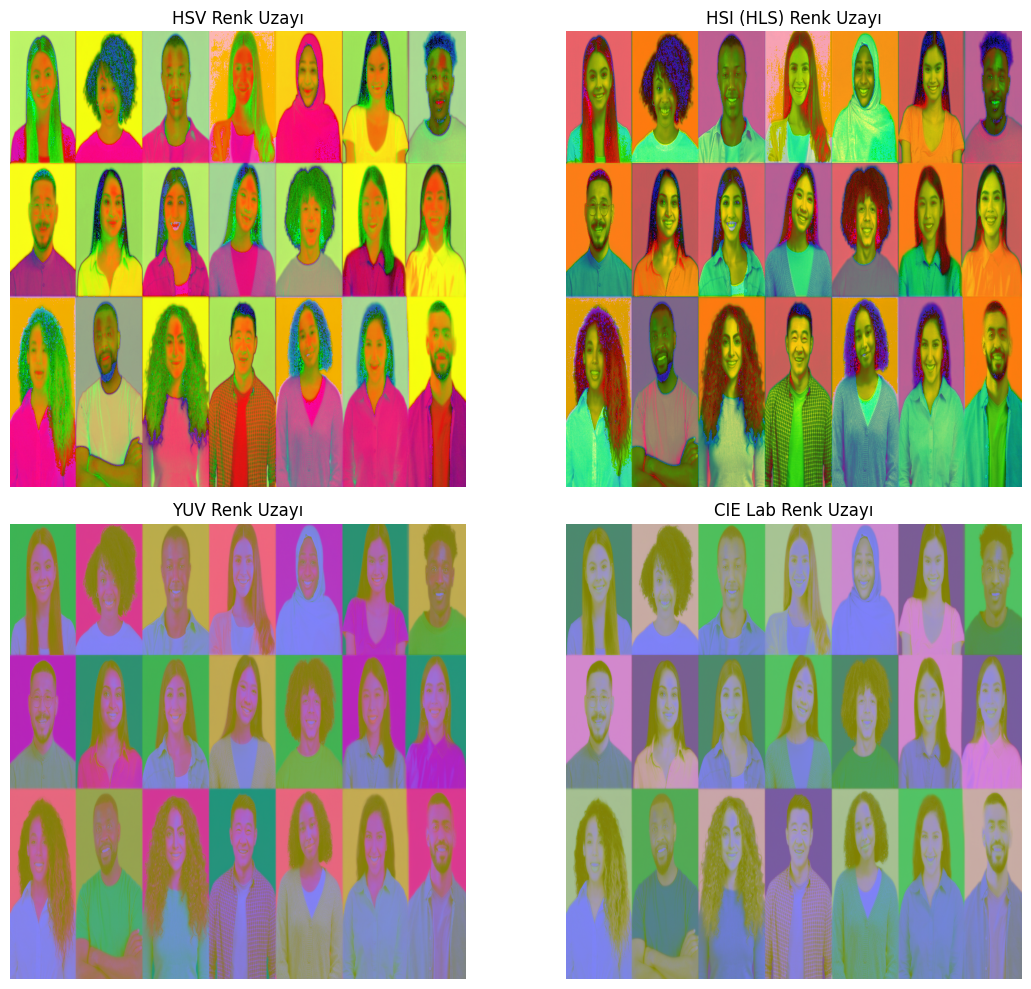

Dönüştürülen görüntüler başarıyla kaydedildi:
- /content/img_hsv.bmp
- /content/img_hls.bmp
- /content/img_yuv.bmp
- /content/img_lab.bmp


In [18]:
import cv2
import matplotlib.pyplot as plt

# 1. RGB renkli BMP görüntüsünü yükleme
img_bmp = cv2.imread('/content/color_1000x1000.bmp') # OpenCV BGR formatında yükler

# Görselleştirme için RGB'ye çevirelim
img_rgb = cv2.cvtColor(img_bmp, cv2.COLOR_BGR2RGB)

# 2. Farklı renk uzaylarına dönüşümler
# HSV Dönüşümü
img_hsv = cv2.cvtColor(img_bmp, cv2.COLOR_BGR2HSV)

# HSI Dönüşümü (OpenCV'de HSI'a en yakın ve matematiksel olarak eşdeğeri HLS uzayıdır)
img_hls = cv2.cvtColor(img_bmp, cv2.COLOR_BGR2HLS)

# YUV Dönüşümü
img_yuv = cv2.cvtColor(img_bmp, cv2.COLOR_BGR2YUV)

# CIE Lab Dönüşümü
img_lab = cv2.cvtColor(img_bmp, cv2.COLOR_BGR2Lab)

# 3. Her birini BMP formatında disk üzerine kaydetme
cv2.imwrite('/content/img_hsv.bmp', img_hsv)
cv2.imwrite('/content/img_hls.bmp', img_hls)
cv2.imwrite('/content/img_yuv.bmp', img_yuv)
cv2.imwrite('/content/img_lab.bmp', img_lab)

# 4. Sonuçları görselleştirme
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(cv2.cvtColor(img_hsv, cv2.COLOR_BGR2RGB)) # Matplotlib RGB gösterdiği için dönüştürerek basıyoruz
axes[0, 0].set_title('HSV Renk Uzayı')
axes[0, 0].axis('off')

axes[0, 1].imshow(cv2.cvtColor(img_hls, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title('HSI (HLS) Renk Uzayı')
axes[0, 1].axis('off')

axes[1, 0].imshow(cv2.cvtColor(img_yuv, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title('YUV Renk Uzayı')
axes[1, 0].axis('off')

axes[1, 1].imshow(cv2.cvtColor(img_lab, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title('CIE Lab Renk Uzayı')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

print("Dönüştürülen görüntüler başarıyla kaydedildi:")
print("- /content/img_hsv.bmp")
print("- /content/img_hls.bmp")
print("- /content/img_yuv.bmp")
print("- /content/img_lab.bmp")

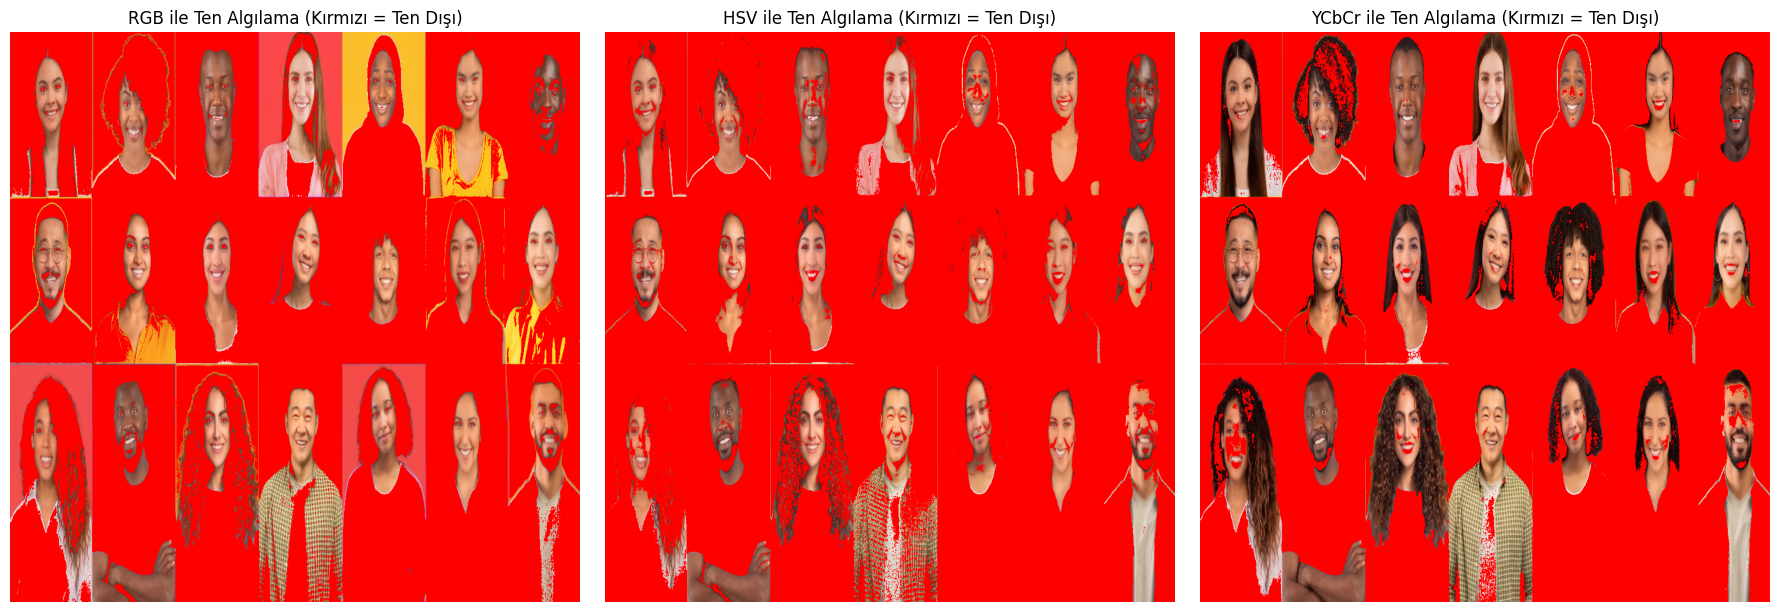

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Görüntüyü yükle ve RGB'ye çevir
img_bgr = cv2.imread('/content/color_1000x1000.bmp')
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# --- 1. RGB Renk Uzayında Ten Tespiti ---
def get_skin_mask_rgb(img):
    R = img[:, :, 0]
    G = img[:, :, 1]
    B = img[:, :, 2]
    # Standart RGB Ten Rengi Kuralları
    rule1 = (R > 95) & (G > 40) & (B > 20) & ((np.maximum(R, np.maximum(G, B)) - np.minimum(R, np.minimum(G, B))) > 15)
    rule2 = (np.abs(R - G) > 15) & (R > G) & (R > B)
    skin_mask = rule1 & rule2
    return skin_mask

# --- 2. HSV Renk Uzayında Ten Tespiti ---
def get_skin_mask_hsv(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    # Klasik HSV ten rengi sınırları (H: 0-20, S: 20-150, V: 60-255)
    lower_skin = np.array([0, 20, 60], dtype=np.uint8)
    upper_skin = np.array([20, 150, 255], dtype=np.uint8)
    mask = cv2.inRange(hsv, lower_skin, upper_skin)
    return mask > 0

# --- 3. YCbCr Renk Uzayında Ten Tespiti ---
def get_skin_mask_ycbcr(img):
    ycbcr = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    # Standart YCbCr ten aralıkları: Y (herhangi), Cb: 77-127, Cr: 133-173
    # OpenCV YCrCb sırasıyla saklar: Y:[:,:,0], Cr:[:,:,1], Cb:[:,:,2]
    lower_skin = np.array([0, 133, 77], dtype=np.uint8)
    upper_skin = np.array([255, 173, 127], dtype=np.uint8)
    mask = cv2.inRange(ycbcr, lower_skin, upper_skin)
    return mask > 0

# Maskeleri hesapla
mask_rgb = get_skin_mask_rgb(img_rgb)
mask_hsv = get_skin_mask_hsv(img_rgb)
mask_ycbcr = get_skin_mask_ycbcr(img_rgb)

# Ten dışı bölgeleri kırmızıya [255, 0, 0] boyama işlemi
img_skin_rgb = img_rgb.copy()
img_skin_rgb[~mask_rgb] = [255, 0, 0]

img_skin_hsv = img_rgb.copy()
img_skin_hsv[~mask_hsv] = [255, 0, 0]

img_skin_ycbcr = img_rgb.copy()
img_skin_ycbcr[~mask_ycbcr] = [255, 0, 0]

# Görselleştirme
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img_skin_rgb)
axes[0].set_title('RGB ile Ten Algılama (Kırmızı = Ten Dışı)')
axes[0].axis('off')

axes[1].imshow(img_skin_hsv)
axes[1].set_title('HSV ile Ten Algılama (Kırmızı = Ten Dışı)')
axes[1].axis('off')

axes[2].imshow(img_skin_ycbcr)
axes[2].set_title('YCbCr ile Ten Algılama (Kırmızı = Ten Dışı)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

```markdown
## Yeni Görsel Üzerinde Tüm Görevlerin Tekrarlanması

Bu adımda, internet üzerinden yüksek kaliteli yeni bir doğa/çiçek temalı test görseli indiriyor ve 1. Görevden itibaren tüm analizlerimizi bu yeni kaynak resim (`/content/new_test_image.jpg`) üzerinden gerçekleştiriyoruz.
```

Yeni test görseli indiriliyor...
Görsel başarıyla indirildi!


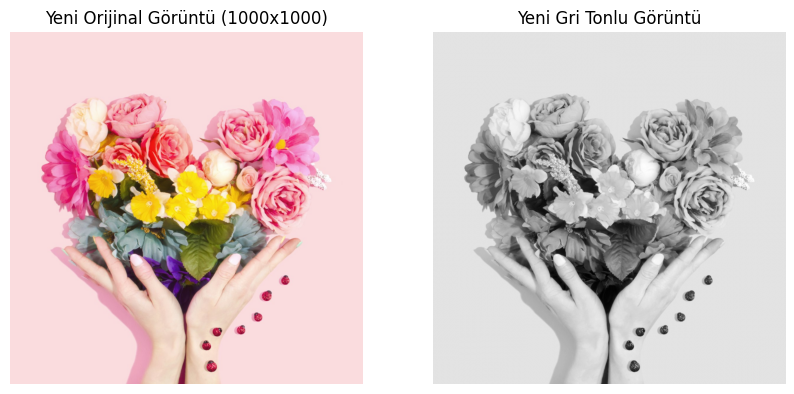

Yeni Renkli BMP Boyutu: 2.8611 MB
Yeni Gri BMP Boyutu: 0.9547 MB
Oran: 3.00 (Beklenen: ~3.0)


In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import os

# 1. Yeni görselin web üzerinden indirilmesi
new_img_url = "https://images.unsplash.com/photo-1526047932273-341f2a7631f9?w=1200&q=80"
new_img_path = "/content/new_test_image.jpg"

try:
    print("Yeni test görseli indiriliyor...")
    urllib.request.urlretrieve(new_img_url, new_img_path)
    print("Görsel başarıyla indirildi!")
except Exception as e:
    print(f"Hata oluştu: {e}")

# 2. Görseli yükleme ve 1000x1000 çözünürlüğe ölçekleme
new_bgr = cv2.imread(new_img_path)
new_rgb = cv2.cvtColor(new_bgr, cv2.COLOR_BGR2RGB)
new_resized_rgb = cv2.resize(new_rgb, (1000, 1000))

# 3. Gri tonlamaya dönüştürme
new_gray = cv2.cvtColor(new_resized_rgb, cv2.COLOR_RGB2GRAY)

# Görselleştirme
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(new_resized_rgb)
plt.title('Yeni Orijinal Görüntü (1000x1000)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(new_gray, cmap='gray')
plt.title('Yeni Gri Tonlu Görüntü')
plt.axis('off')
plt.show()

# BMP formatında kaydetme
new_color_bmp = '/content/new_color_1000x1000.bmp'
new_gray_bmp = '/content/new_gray_1000x1000.bmp'

cv2.imwrite(new_color_bmp, cv2.cvtColor(new_resized_rgb, cv2.COLOR_RGB2BGR))
cv2.imwrite(new_gray_bmp, new_gray)

# Dosya boyutları kontrolü
new_color_size = os.path.getsize(new_color_bmp) / (1024 * 1024)
new_gray_size = os.path.getsize(new_gray_bmp) / (1024 * 1024)

print(f"Yeni Renkli BMP Boyutu: {new_color_size:.4f} MB")
print(f"Yeni Gri BMP Boyutu: {new_gray_size:.4f} MB")
print(f"Oran: {new_color_size / new_gray_size:.2f} (Beklenen: ~3.0)")

```markdown
### Task-4: Yeni Görsel Üzerinde Renk Uzayı Dönüşümleri

Şimdi indirdiğimiz yeni çiçek görselimizi **HSV**, **HSI (HLS)**, **YUV** ve **CIE Lab** renk uzaylarına dönüştürüyoruz.
```

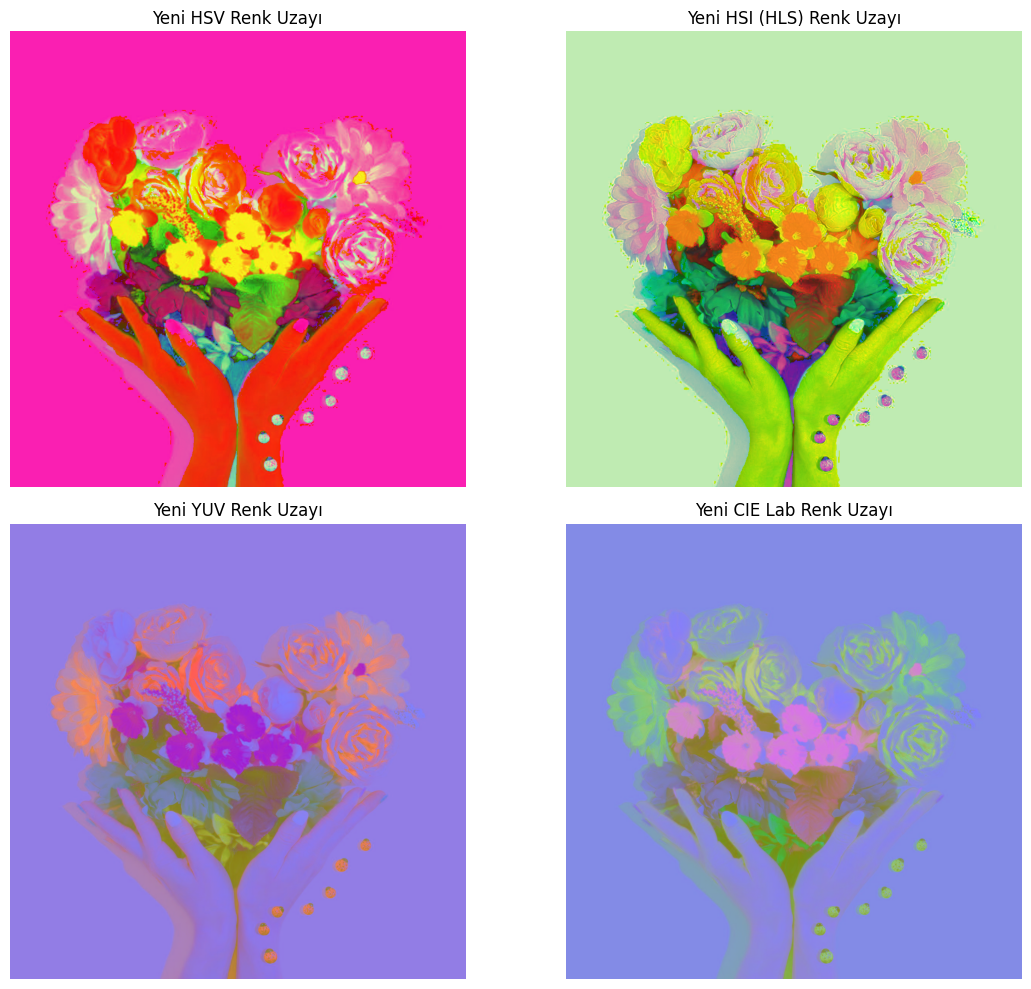

In [21]:
# Dönüşümler
new_hsv = cv2.cvtColor(new_bgr, cv2.COLOR_BGR2HSV)
new_hls = cv2.cvtColor(new_bgr, cv2.COLOR_BGR2HLS)
new_yuv = cv2.cvtColor(new_bgr, cv2.COLOR_BGR2YUV)
new_lab = cv2.cvtColor(new_bgr, cv2.COLOR_BGR2Lab)

# Kayıt işlemleri
cv2.imwrite('/content/new_img_hsv.bmp', new_hsv)
cv2.imwrite('/content/new_img_hls.bmp', new_hls)
cv2.imwrite('/content/new_img_yuv.bmp', new_yuv)
cv2.imwrite('/content/new_img_lab.bmp', new_lab)

# Görselleştirme
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes[0, 0].imshow(cv2.cvtColor(new_hsv, cv2.COLOR_BGR2RGB))
axes[0, 0].set_title('Yeni HSV Renk Uzayı')
axes[0, 0].axis('off')

axes[0, 1].imshow(cv2.cvtColor(new_hls, cv2.COLOR_BGR2RGB))
axes[0, 1].set_title('Yeni HSI (HLS) Renk Uzayı')
axes[0, 1].axis('off')

axes[1, 0].imshow(cv2.cvtColor(new_yuv, cv2.COLOR_BGR2RGB))
axes[1, 0].set_title('Yeni YUV Renk Uzayı')
axes[1, 0].axis('off')

axes[1, 1].imshow(cv2.cvtColor(new_lab, cv2.COLOR_BGR2RGB))
axes[1, 1].set_title('Yeni CIE Lab Renk Uzayı')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

### Task-5: Yeni Görsel Üzerinde Çiçek Segmentasyonu Karşılaştırması

Yeni doğa görselimizdeki canlı pembe/kırmızı çiçek alanlarını segmente etmek için **RGB**, **HSV** ve **YCbCr** renk uzaylarında maskeler oluşturuyoruz. Çiçek dışındaki tüm alanları saf mavi (`[0, 0, 255]`) renge boyayarak maskelerin kalitesini inceliyoruz.

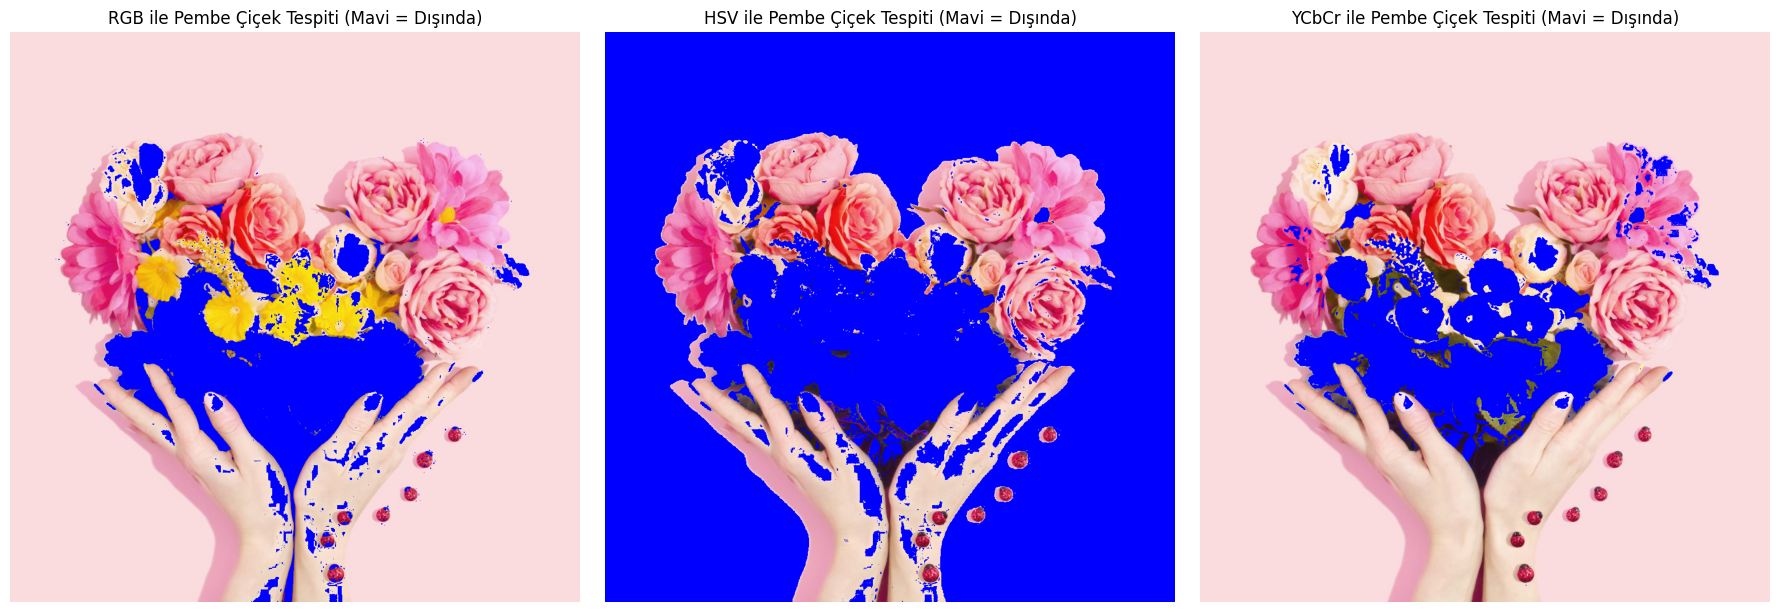

In [22]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Yeni 1000x1000 RGB görselimiz
img_rgb = cv2.imread('/content/new_color_1000x1000.bmp')
img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB)

# 1. RGB Uzayında Pembe/Kırmızı Tonları Algılama
def get_flower_mask_rgb(img):
    R = img[:, :, 0].astype(np.int16)
    G = img[:, :, 1].astype(np.int16)
    B = img[:, :, 2].astype(np.int16)
    # Pembe/Kırmızı için kırmızı kanalın yeşil ve maviden yüksek olması beklenir
    mask = (R > 130) & (R > G + 20) & (R > B - 20)
    return mask

# 2. HSV Uzayında Pembe/Kırmızı Tonları Algılama
def get_flower_mask_hsv(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    # Pembe ve kırmızı tonları için iki farklı H aralığını birleştiriyoruz
    lower_red1 = np.array([0, 40, 40])
    upper_red1 = np.array([15, 255, 255])
    lower_red2 = np.array([140, 40, 40])
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
    return (mask1 | mask2) > 0

# 3. YCbCr Uzayında Pembe/Kırmızı Tonları Algılama
def get_flower_mask_ycbcr(img):
    ycbcr = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    # Kırmızı/Pembe tonları için yüksek Cr (kırmızı farkı) bileşeni aranır
    lower_pink = np.array([0, 135, 80])
    upper_pink = np.array([255, 255, 140])
    mask = cv2.inRange(ycbcr, lower_pink, upper_pink)
    return mask > 0

# Maskeleri uygula
mask_rgb = get_flower_mask_rgb(img_rgb)
mask_hsv = get_flower_mask_hsv(img_rgb)
mask_ycbcr = get_flower_mask_ycbcr(img_rgb)

# Maskelenmiş görselleri hazırla
img_seg_rgb = img_rgb.copy()
img_seg_rgb[~mask_rgb] = [0, 0, 255]

img_seg_hsv = img_rgb.copy()
img_seg_hsv[~mask_hsv] = [0, 0, 255]

img_seg_ycbcr = img_rgb.copy()
img_seg_ycbcr[~mask_ycbcr] = [0, 0, 255]

# Sonuçları görselleştirme
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img_seg_rgb)
axes[0].set_title('RGB ile Pembe Çiçek Tespiti (Mavi = Dışında)')
axes[0].axis('off')

axes[1].imshow(img_seg_hsv)
axes[1].set_title('HSV ile Pembe Çiçek Tespiti (Mavi = Dışında)')
axes[1].axis('off')

axes[2].imshow(img_seg_ycbcr)
axes[2].set_title('YCbCr ile Pembe Çiçek Tespiti (Mavi = Dışında)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

```markdown
### Task-5: Yeni Görsel Üzerinde Çiçek/Renk Segmentasyonu Karşılaştırması

Yeni doğa görselimizdeki canlı pembe/kırmızı çiçek alanlarını segmente etmek için **RGB**, **HSV** ve **YCbCr** renk uzaylarında maskeler oluşturuyoruz. Çiçek dışındaki tüm alanları saf kırmızı (`[255, 0, 0]`) renge boyayarak maskelerin kalitesini inceliyoruz.
```

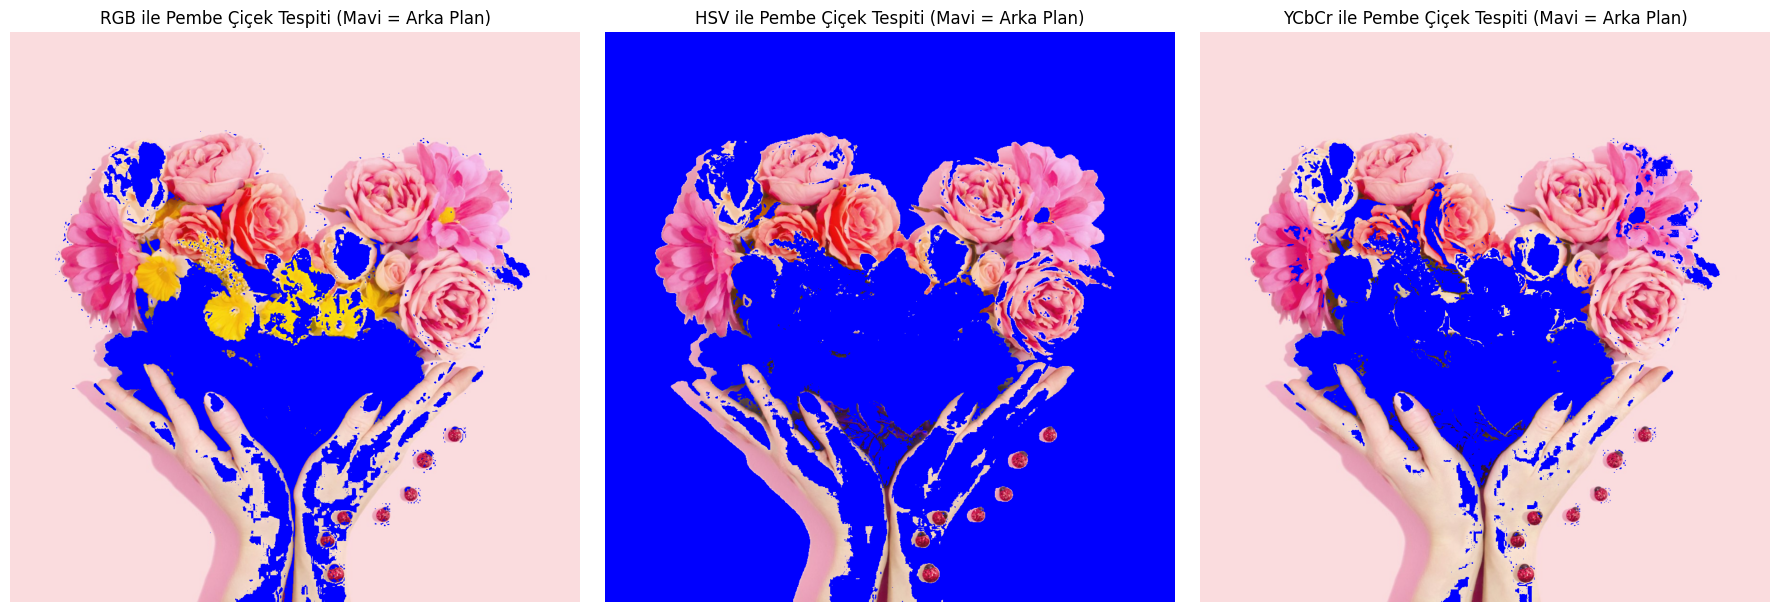

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Yeni 1000x1000 RGB görselimiz
img_rgb = cv2.imread('/content/new_color_1000x1000.bmp')
img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB)

# 1. RGB Uzayında Pembe/Kırmızı Tonları Algılama
def get_flower_mask_rgb(img):
    R = img[:, :, 0].astype(np.int16)
    G = img[:, :, 1].astype(np.int16)
    B = img[:, :, 2].astype(np.int16)
    # Pembe/Kırmızı için kırmızı kanalın yeşil ve maviden belirgin şekilde yüksek olması beklenir
    mask = (R > 130) & (R > G + 25) & (R > B - 20)
    return mask

# 2. HSV Uzayında Pembe/Kırmızı Tonları Algılama
def get_flower_mask_hsv(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)
    # Pembe ve kırmızı tonları için iki farklı H aralığını birleştiriyoruz (Kırmızı H dairesinin iki ucundadır)
    lower_red1 = np.array([0, 50, 50])
    upper_red1 = np.array([15, 255, 255])
    lower_red2 = np.array([140, 50, 50])
    upper_red2 = np.array([180, 255, 255])

    mask1 = cv2.inRange(hsv, lower_red1, upper_red1)
    mask2 = cv2.inRange(hsv, lower_red2, upper_red2)
    return (mask1 | mask2) > 0

# 3. YCbCr Uzayında Pembe/Kırmızı Tonları Algılama
def get_flower_mask_ycbcr(img):
    ycbcr = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    # Kırmızı/Pembe tonları için yüksek Cr (kırmızı farkı) bileşeni aranır
    # Cr: [:, :, 1], Cb: [:, :, 2]
    lower_pink = np.array([0, 140, 100])
    upper_pink = np.array([255, 255, 140])
    mask = cv2.inRange(ycbcr, lower_pink, upper_pink)
    return mask > 0

# Maskeleri uygula
mask_rgb = get_flower_mask_rgb(img_rgb)
mask_hsv = get_flower_mask_hsv(img_rgb)
mask_ycbcr = get_flower_mask_ycbcr(img_rgb)

# Maskelenmiş görselleri hazırla (Pembe çiçek dışı alanları parlak maviye boyayalım ki net ayırt edilsin)
# Pembe çiçeklerin kendisi zaten kırmızıya yakın olduğu için arka planı mavi [0, 0, 255] yapıyoruz
img_seg_rgb = img_rgb.copy()
img_seg_rgb[~mask_rgb] = [0, 0, 255]

img_seg_hsv = img_rgb.copy()
img_seg_hsv[~mask_hsv] = [0, 0, 255]

img_seg_ycbcr = img_rgb.copy()
img_seg_ycbcr[~mask_ycbcr] = [0, 0, 255]

# Sonuçları görselleştirme
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img_seg_rgb)
axes[0].set_title('RGB ile Pembe Çiçek Tespiti (Mavi = Arka Plan)')
axes[0].axis('off')

axes[1].imshow(img_seg_hsv)
axes[1].set_title('HSV ile Pembe Çiçek Tespiti (Mavi = Arka Plan)')
axes[1].axis('off')

axes[2].imshow(img_seg_ycbcr)
axes[2].set_title('YCbCr ile Pembe Çiçek Tespiti (Mavi = Arka Plan)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

### Task-3: Yeni Akış için 8K Çözünürlük Performans Ölçümü

8K (7680x4320) boyutlarında 3 kanallı bir matris oluşturup, bu matrisin elemanlarını 2'ye bölme işleminin ne kadar sürdüğünü hassas bir şekilde test ediyoruz.

In [24]:
import cv2
import numpy as np
import time

# 8K boyutlarında rastgele gürültü içeren bir dizi oluşturma
width, height = 7680, 4320
new_8k_array = np.random.randint(0, 256, (height, width, 3), dtype=np.uint8)

# Performans testi
start_t = time.perf_counter()

# NumPy optimize edilmiş tam sayı bölmesi
processed_8k = new_8k_array // 2

end_t = time.perf_counter()
elapsed_ms = (end_t - start_t) * 1000

print(f"--- 8K Çözünürlük Hız Testi Sonucu ---")
print(f"Matris Boyutu: {new_8k_array.shape[1]} x {new_8k_array.shape[0]}")
print(f"İşlem Süresi: {elapsed_ms:.2f} milisaniye")

--- 8K Çözünürlük Hız Testi Sonucu ---
Matris Boyutu: 7680 x 4320
İşlem Süresi: 30.56 milisaniye


### Task-3: Yeni Akış için 8K Çözünürlük Performans Ölçümü

8K (7680x4320) boyutlarında 3 kanallı bir matris oluşturup, bu matrisin elemanlarını 2'ye bölme işleminin ne kadar sürdüğünü hassas bir şekilde test ediyoruz.

In [25]:
import cv2
import numpy as np
import time

# 8K boyutlarında rastgele gürültü içeren bir dizi oluşturma
width, height = 7680, 4320
new_8k_array = np.random.randint(0, 256, (height, width, 3), dtype=np.uint8)

# Performans testi
start_t = time.perf_counter()

# NumPy optimize edilmiş tam sayı bölmesi
processed_8k = new_8k_array // 2

end_t = time.perf_counter()
elapsed_ms = (end_t - start_t) * 1000

print(f"--- 8K Çözünürlük Hız Testi Sonucu ---")
print(f"Matris Boyutu: {new_8k_array.shape[1]} x {new_8k_array.shape[0]}")
print(f"İşlem Süresi: {elapsed_ms:.2f} milisaniye")

--- 8K Çözünürlük Hız Testi Sonucu ---
Matris Boyutu: 7680 x 4320
İşlem Süresi: 31.25 milisaniye
